1 - Cinza


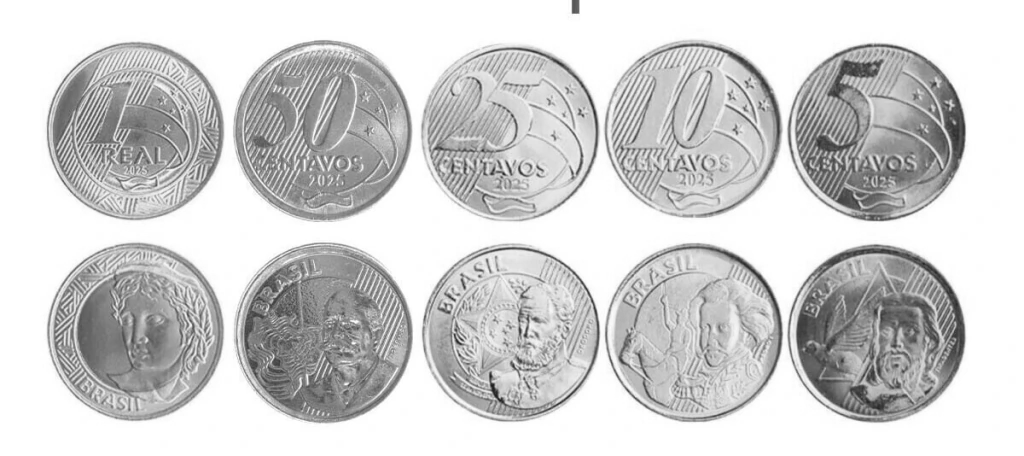

2 - Desfoque


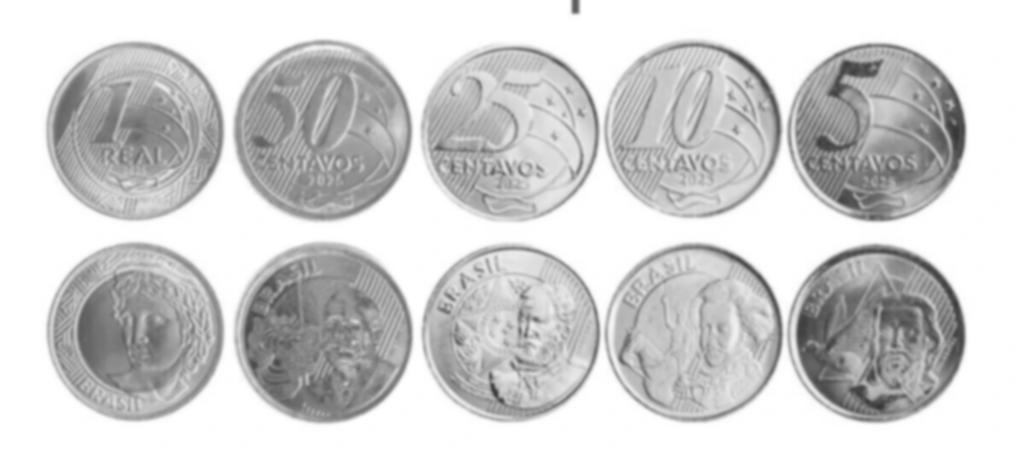

3 - Limiarizada (Binária)


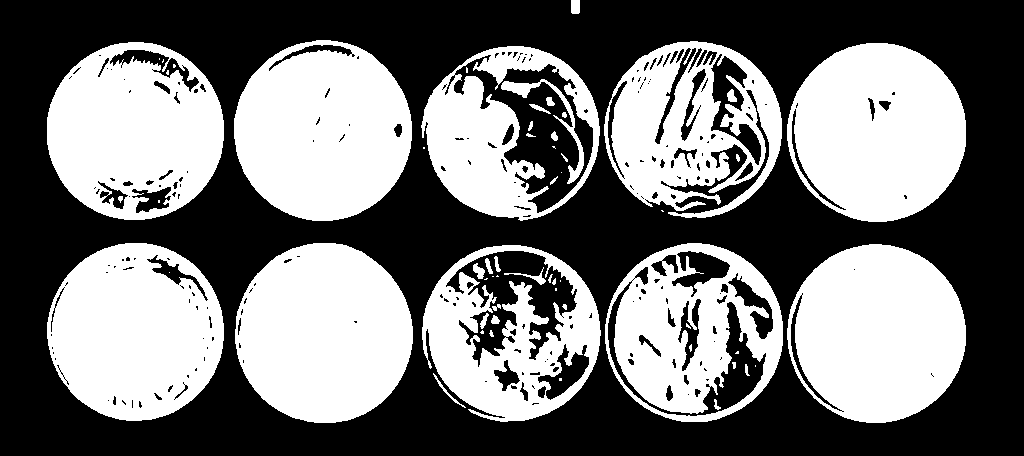

Número de objetos encontrados: 15
4 - Contornos Desenhados


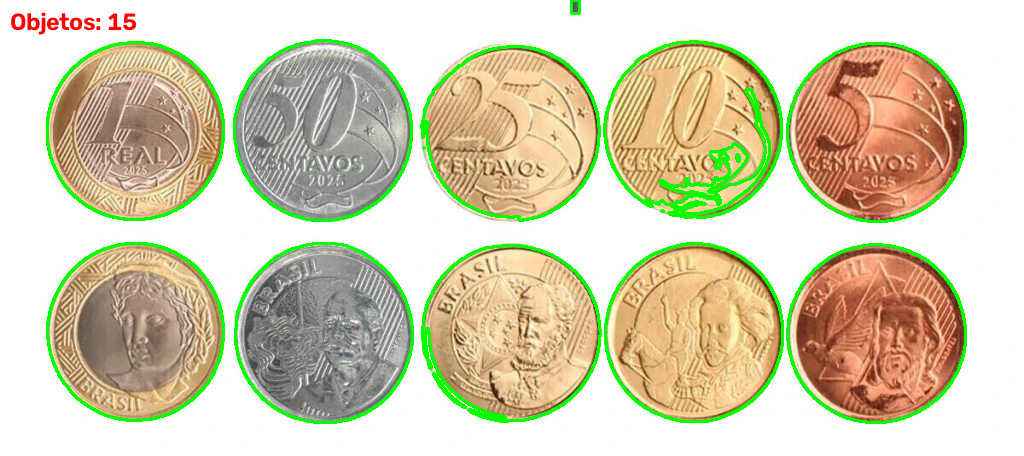

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Caminho para a sua imagem com objetos
caminho_imagem = '/content/whatsapp-image-2026-07-22-at-14-04-15-b69f8b91cd493e7a2b17847401404613-1024-1024.webp'

# 1. Carregar a Imagem
img_original = cv2.imread(caminho_imagem)
if img_original is None:
    print(f"Erro: Não foi possível carregar a imagem em '{caminho_imagem}'")
else:
    img_para_desenhar = img_original.copy() # Copia para desenhar os contornos

    # 2. Pré-processamento
    # a. Converter para Tons de Cinza
    img_cinza = cv2.cvtColor(img_original, cv2.COLOR_BGR2GRAY)
    print('1 - Cinza')
    cv2_imshow(img_cinza)

    # b. Aplicar Desfoque Gaussiano
    img_blur = cv2.GaussianBlur(img_cinza, (7, 7), 0)
    print('2 - Desfoque')
    cv2_imshow(img_blur)

    # c. Limiarização
    _, img_thresh = cv2.threshold(img_blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    print('3 - Limiarizada (Binária)')
    cv2_imshow(img_thresh)

    # 3. Encontrar Contornos
    contornos, hierarquia = cv2.findContours(img_thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # 4. Contar Contornos
    numero_de_objetos = len(contornos)
    print(f"Número de objetos encontrados: {numero_de_objetos}")

    # 5. Desenhar Contornos (para visualização)
    cv2.drawContours(img_para_desenhar, contornos, -1, (0, 255, 0), 2)

    # Adicionar texto com a contagem na imagem
    cv2.putText(img_para_desenhar, f"Objetos: {numero_de_objetos}", (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
    print('4 - Contornos Desenhados')
    cv2_imshow(img_para_desenhar)